In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Warmup

## Load Data

In [2]:
files = sorted(Path("Data").glob("*.csv"))

df = pd.concat(
    (pd.read_csv(
        f, 
        parse_dates=["started_at", "ended_at"], 
        dtype={"start_station_id": str, "end_station_id": str}
    ) for f in files),
    ignore_index=True,
)

df_raw_shape = df.shape
print(df_raw_shape)
df.head()

(5246236, 13)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E4A8132DACF670C3,electric_bike,2026-08-10 14:31:22.100,2026-08-10 14:37:37.034,E 33 St & 5 Ave,6322.01,W 24 St & 7 Ave,6257.03,40.747659,-73.984907,40.744876,-73.995299,member
1,8382768C05C30BB4,electric_bike,2026-08-10 08:04:28.348,2026-08-10 08:33:27.680,Emerson Pl & Myrtle Ave,4683.02,W 24 St & 7 Ave,6257.03,40.693631,-73.962236,40.744876,-73.995299,member
2,3A1C43832BBE4FCD,classic_bike,2026-08-08 19:36:32.350,2026-08-08 19:43:47.890,Broadway & E 19 St,5980.11,W 24 St & 7 Ave,6257.03,40.738290,-73.990060,40.744876,-73.995299,member
3,5C9BC6DFC4DEA183,electric_bike,2026-08-05 14:34:27.749,2026-08-05 14:46:23.526,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member
4,355579CC64D1BE20,electric_bike,2026-08-01 14:16:44.531,2026-08-01 14:29:39.539,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member


## Cleaning

In [3]:
# Add a new column "ride_time" to the dataframe
df['ride_time'] = df['ended_at'] - df['started_at']

# Generate a boolean mask for each condition (too long, or negative)
long_ride_times = df["ride_time"] > pd.Timedelta(hours=3)
print("longer than 3 hours:", long_ride_times.sum())        # sum() counts all true values in the mask

negative_ride_times = df["ride_time"] < pd.Timedelta(0)
print("negative ride times:", negative_ride_times.sum())

missing_station = df["start_station_id"].isna() | df["end_station_id"].isna()
print("missing start/end station:", missing_station.sum())

df = df.loc[~(long_ride_times | negative_ride_times | missing_station)]
df_clean_shape = df.shape

print(f"before: {df_raw_shape}")
print(f"after: {df_clean_shape}")
print(f"dropped: {df_raw_shape[0] - df_clean_shape[0]} rows")

longer than 3 hours: 6020
negative ride times: 0
missing start/end station: 17156
before: (5246236, 13)
after: (5225284, 14)
dropped: 20952 rows


## 1) Histogram

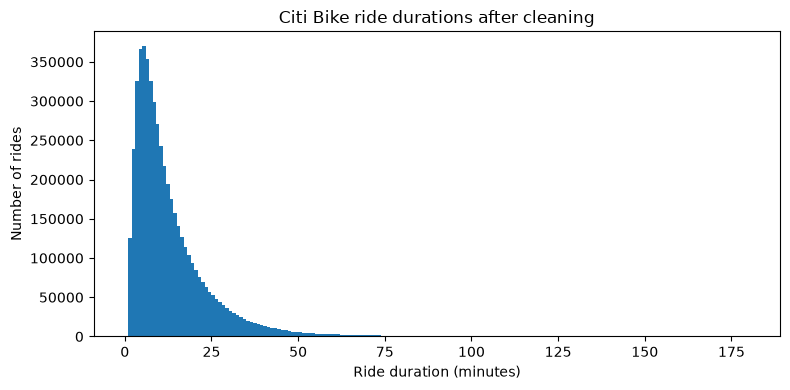

In [4]:
minutes = df["ride_time"].dt.total_seconds() / 60

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(minutes, bins=180, range=(0, 180))
ax.set_xlabel("Ride duration (minutes)")
ax.set_ylabel("Number of rides")
ax.set_title("Citi Bike ride durations after cleaning")
plt.tight_layout()
plt.show()

## 2) Expected time, and Variance

In [5]:
ride_times_in_minutes = df["ride_time"].dt.total_seconds() / 60

E_x = np.mean(ride_times_in_minutes)
Var_x = np.var(ride_times_in_minutes)
P_g20 = (ride_times_in_minutes > 20).sum() / df.shape[0]

print(f"E[X]: {E_x}")
print(f"Var[X]: {Var_x}")
print(f"P(X > 20): {P_g20}")

E[X]: 13.407342967224366
Var[X]: 157.21753576844358
P(X > 20): 0.18799016474511243


## 3) Conditional: P(X > 20 | Member)

In [6]:
# Citibike Members
citibike_member_rides = df["member_casual"] == "member"
P_member = citibike_member_rides.sum() / df.shape[0]

# Member, and ride longer than 20 minutes
citibike_member_and_g20_rides = (df["member_casual"] == "member") & ((df["ride_time"].dt.total_seconds() / 60) > 20)
P_g20_and_member = citibike_member_and_g20_rides.sum() / df.shape[0]

# P(X > 20 | Member)
P_g20_given_member = P_g20_and_member / P_member

print(f"P(X > 20 | Member): {P_g20_given_member}")

P(X > 20 | Member): 0.15331187684384096


## 4) P(member | X > 25)

In [7]:
p_joint = ((df["member_casual"] == "member") & ((df["ride_time"].dt.total_seconds() / 60) > 25)).sum()  # P(A and B)
p_ride_25_min = ((df["ride_time"].dt.total_seconds() / 60) > 25).sum()                                  # P(B)
print(f"P(member | ride > 25 min) = {p_joint / p_ride_25_min:.4f}")

P(member | ride > 25 min) = 0.6030


## 5) expected ride duration by bike type

In [8]:
electric_average_ride_time = df.loc[df["rideable_type"] == "electric_bike", "ride_time"].mean().total_seconds() / 60
classic_average_ride_time = df.loc[df["rideable_type"] == "classic_bike", "ride_time"].mean().total_seconds() / 60
print(f"Expected electric bike ride time: {electric_average_ride_time:.2f} min")
print(f"Expected classic bike ride time: {classic_average_ride_time:.2f} min")

Expected electric bike ride time: 13.36 min
Expected classic bike ride time: 13.54 min


## 6) P(bike type | X < 10)

In [9]:
short = df["ride_time"] < pd.Timedelta(minutes=10)
p_ride_less_than_10 = short.mean()                                      # P(B)

p_joint = ((df["rideable_type"] == "electric_bike") & short).mean()     # P(A and B)
print(f"P(Electric Bike | Ride < 10) = {p_joint / p_ride_less_than_10:.2f}")

p_joint = ((df["rideable_type"] == "classic_bike") & short).mean()
print(f"P(Classic Bike | Ride < 10) = {p_joint / p_ride_less_than_10:.2f}")

p_electric = (df["rideable_type"] == "electric_bike").mean()
print(f"P(Electric Bike) overall = {p_electric:.2f}")

P(Electric Bike | Ride < 10) = 0.72
P(Classic Bike | Ride < 10) = 0.28
P(Electric Bike) overall = 0.73


# Part I: Modeling Citi Bike stations using Markov chains

## Selected Variables

In [10]:
AM_HOURS = range(6, 11)         # 6:00–10:59
PM_HOURS = range(15, 20)        # 15:00–19:59
HOURS = list(AM_HOURS) + list(PM_HOURS)
stations = [
    "W 21 St & 6 Ave", 
    "11 Ave & W 41 St", 
    "S 2 St & Kent Ave"
    ]
station_capacities = [63, 48, 44]
WINDOWS_TO_TEST = [5, 10, 15, 20, 25, 30]
WINDOW = 10                     # number of minutes between windows

## Station Selection

In [11]:
def block_flows(df, hours):
    dep_mask = (df["started_at"].dt.dayofweek < 5) & df["started_at"].dt.hour.isin(hours)
    arr_mask = (df["ended_at"].dt.dayofweek < 5) & df["ended_at"].dt.hour.isin(hours)
    dep = df.loc[dep_mask].groupby("start_station_name").size()
    arr = df.loc[arr_mask].groupby("end_station_name").size()
    out = pd.DataFrame({"dep": dep, "arr": arr}).fillna(0)
    out["net"] = out["arr"] - out["dep"]
    out["total"] = out["arr"] + out["dep"]
    return out

am = block_flows(df, AM_HOURS)
pm = block_flows(df, PM_HOURS)

summary = am.add_suffix("_am").join(pm.add_suffix("_pm"), how="outer").fillna(0)
summary["total"] = summary["total_am"] + summary["total_pm"]
summary.sort_values("total", ascending=False).head(25)

,dep_am,arr_am,net_am,total_am,dep_pm,arr_pm,net_pm,total_pm,total
W 21 St & 6 Ave,2800.0,3948.0,1148.0,6748.0,5603.0,4589.0,-1014.0,10192.0,16940.0
9 Ave & W 33 St,2404.0,5117.0,2713.0,7521.0,5747.0,3300.0,-2447.0,9047.0,16568.0
Pier 61 at Chelsea Piers,2984.0,2905.0,-79.0,5889.0,5109.0,4838.0,-271.0,9947.0,15836.0
W 31 St & 7 Ave,2806.0,2847.0,41.0,5653.0,4432.0,4692.0,260.0,9124.0,14777.0
Park Ave & E 42 St,2733.0,3931.0,1198.0,6664.0,4246.0,3384.0,-862.0,7630.0,14294.0
E 17 St & Broadway,2128.0,3424.0,1296.0,5552.0,4662.0,3642.0,-1020.0,8304.0,13856.0
6 Ave & W 33 St,2286.0,2176.0,-110.0,4462.0,3949.0,4326.0,377.0,8275.0,12737.0
Broadway & W 25 St,1377.0,3189.0,1812.0,4566.0,4838.0,3174.0,-1664.0,8012.0,12578.0
1 Ave & E 68 St,2004.0,4009.0,2005.0,6013.0,4175.0,2135.0,-2040.0,6310.0,12323.0
Broadway & E 14 St,1905.0,2805.0,900.0,4710.0,4032.0,3413.0,-619.0,7445.0,12155.0


1. W 21 St & 6 Ave	  (Morning Surplus, Midtown, 63 Docks)
2. 11 Ave & W 41 St     (Afternoon Surplus, Lower Midtown, 48 Docks)
3. S 2 St & Kent Ave	   (Brooklyn, Roughly Equal in/out, 44 Docks)

## Data Consolidation

In [12]:
print("Our stations:")
for station in stations:
    print(f"  {station}")
print(f"\nKeeping only rides that occur Mon-Fri, "
      f"{AM_HOURS.start}:00 - {AM_HOURS.stop - 1}:59 or {PM_HOURS.start}:00 - {PM_HOURS.stop - 1}:59")

# Remove all rides that fall outside our time windows
start_in_window = (df["started_at"].dt.dayofweek < 5) & df["started_at"].dt.hour.isin(HOURS)
end_in_window   = (df["ended_at"].dt.dayofweek < 5)   & df["ended_at"].dt.hour.isin(HOURS)
outside_window = ~(start_in_window | end_in_window)
print(f"removed {outside_window.sum()} rides outside weekday time windows")
df = df.loc[~outside_window]

# Remove all rides that do not start or end at one of our stations
at_our_stations = df["start_station_name"].isin(stations) | df["end_station_name"].isin(stations)
print(f"removed {(~at_our_stations).sum()} rides not starting or ending at our stations")
df = df.loc[at_our_stations]

# Print old vs new shape of df
df_filtered_shape = df.shape
print(f"before: {df_clean_shape}")
print(f"after: {df_filtered_shape}\n")



# Count and print number of arrivals and departures by each station
dep_mask = df["start_station_name"].isin(stations) & df["started_at"].dt.hour.isin(HOURS) & (df["started_at"].dt.dayofweek < 5)
arr_mask = df["end_station_name"].isin(stations) & df["ended_at"].dt.hour.isin(HOURS) & (df["ended_at"].dt.dayofweek < 5)
counts = pd.DataFrame({
    "departures": df.loc[dep_mask, "start_station_name"].value_counts(),
    "arrivals":   df.loc[arr_mask, "end_station_name"].value_counts(),
}).reindex(stations).fillna(0).astype(int)
counts["total"] = counts["departures"] + counts["arrivals"]

name_width = max(len(s) for s in stations)
for station, r in counts.iterrows():
    print(f"{station:<{name_width}} | arrivals: {r['arrivals']:>5} | departures: {r['departures']:>5} | total: {r['total']:>5}")

Our stations:
  W 21 St & 6 Ave
  11 Ave & W 41 St
  S 2 St & Kent Ave

Keeping only rides that occur Mon-Fri, 6:00 - 10:59 or 15:00 - 19:59
removed 3014905 rides outside weekday time windows
removed 2170481 rides not starting or ending at our stations
before: (5225284, 14)
after: (39898, 14)

W 21 St & 6 Ave   | arrivals:  8537 | departures:  8403 | total: 16940
11 Ave & W 41 St  | arrivals:  5559 | departures:  5913 | total: 11472
S 2 St & Kent Ave | arrivals:  5495 | departures:  5402 | total: 10897


## State Space, Time Step, etc Exploration

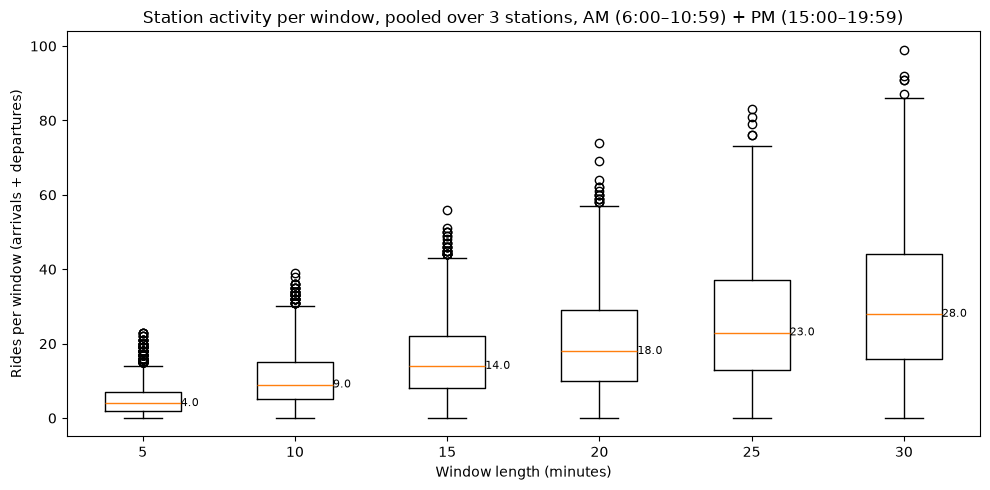

In [13]:
# Claude generated code. Box and whisker plot of the number of rides per window (arrivals + departures),
# pooled across all stations and both blocks, for each window length in WINDOWS_TO_TEST.

assert len(AM_HOURS) == len(PM_HOURS), "AM and PM blocks must be the same length"
BLOCK_LEN = len(AM_HOURS) * 60     # minutes per block

# Uses dep_mask / arr_mask from the arrivals/departures count cell above
dep = df.loc[dep_mask, ["start_station_name", "started_at"]].set_axis(["station", "time"], axis=1)
arr = df.loc[arr_mask, ["end_station_name", "ended_at"]].set_axis(["station", "time"], axis=1)
events = pd.concat([dep, arr], ignore_index=True)

# Which day and block each event is in, and how many minutes into the block it happened
events["date"] = events["time"].dt.normalize()
events["block"] = np.where(events["time"].dt.hour.isin(AM_HOURS), "AM", "PM")
block_start_min = np.where(events["block"] == "AM", AM_HOURS.start, PM_HOURS.start) * 60
events["offset"] = events["time"].dt.hour * 60 + events["time"].dt.minute - block_start_min

days = sorted(events["date"].unique())
box_data = []

for L in WINDOWS_TO_TEST:
    n_windows = -(-BLOCK_LEN // L)          # round up so a partial window is included
    counts = (events.assign(window=events["offset"] // L)
                    .groupby(["station", "date", "block", "window"]).size())

    # Fill in windows with no events as 0
    full_grid = pd.MultiIndex.from_product(
        [stations, days, ["AM", "PM"], range(n_windows)], names=counts.index.names)
    counts = counts.reindex(full_grid, fill_value=0).astype(float)

    # Scale up a partial last window (e.g. 20 of 40 min → ×2)
    leftover = BLOCK_LEN % L
    if leftover:
        last = counts.index.get_level_values("window") == n_windows - 1
        counts.loc[last] *= L / leftover

    box_data.append(counts.values)

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(box_data)
for i, d in enumerate(box_data, start=1):
    med = np.median(d)
    ax.text(i + 0.25, med, f"{med:.1f}", va="center", fontsize=8)
ax.set_xticks(range(1, len(WINDOWS_TO_TEST) + 1), [str(L) for L in WINDOWS_TO_TEST])
ax.set_xlabel("Window length (minutes)")
ax.set_ylabel("Rides per window (arrivals + departures)")
ax.set_title(f"Station activity per window, pooled over {len(stations)} stations, "
             f"AM ({AM_HOURS.start}:00–{AM_HOURS.stop - 1}:59) + PM ({PM_HOURS.start}:00–{PM_HOURS.stop - 1}:59)")
plt.tight_layout()
plt.show()

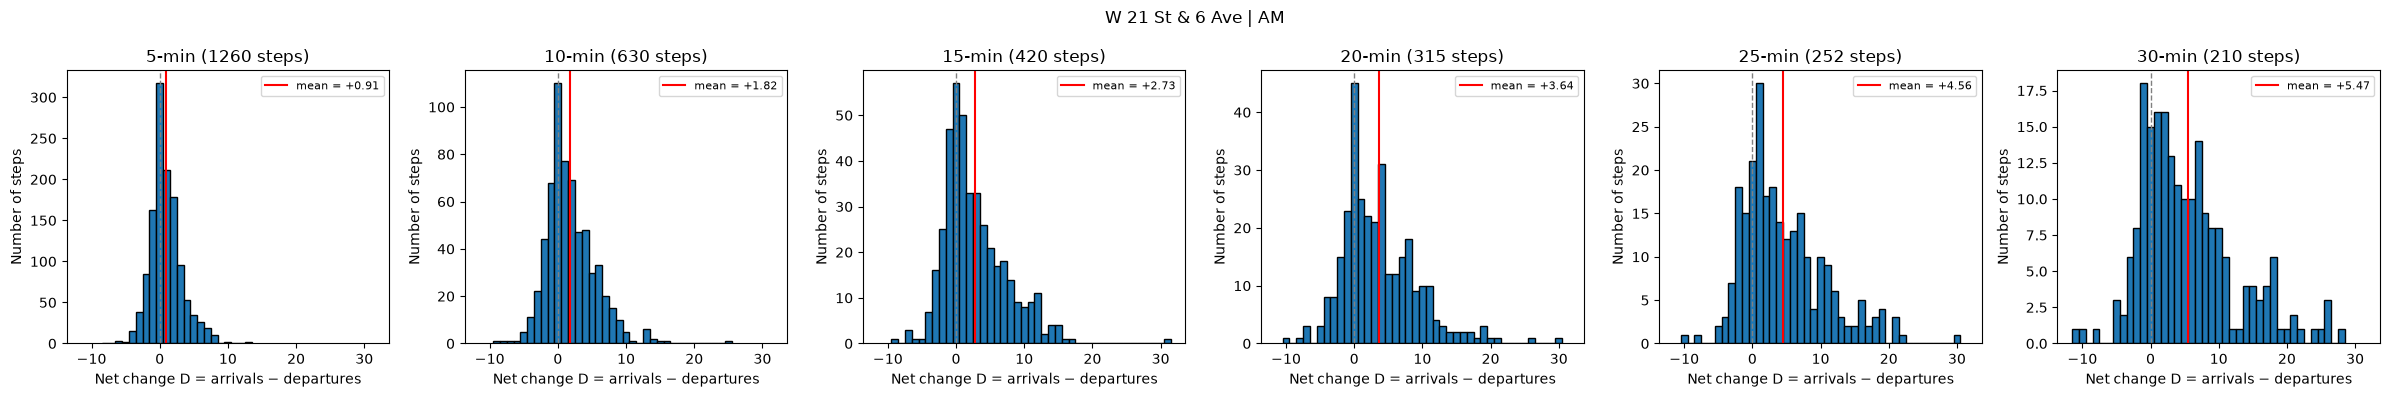

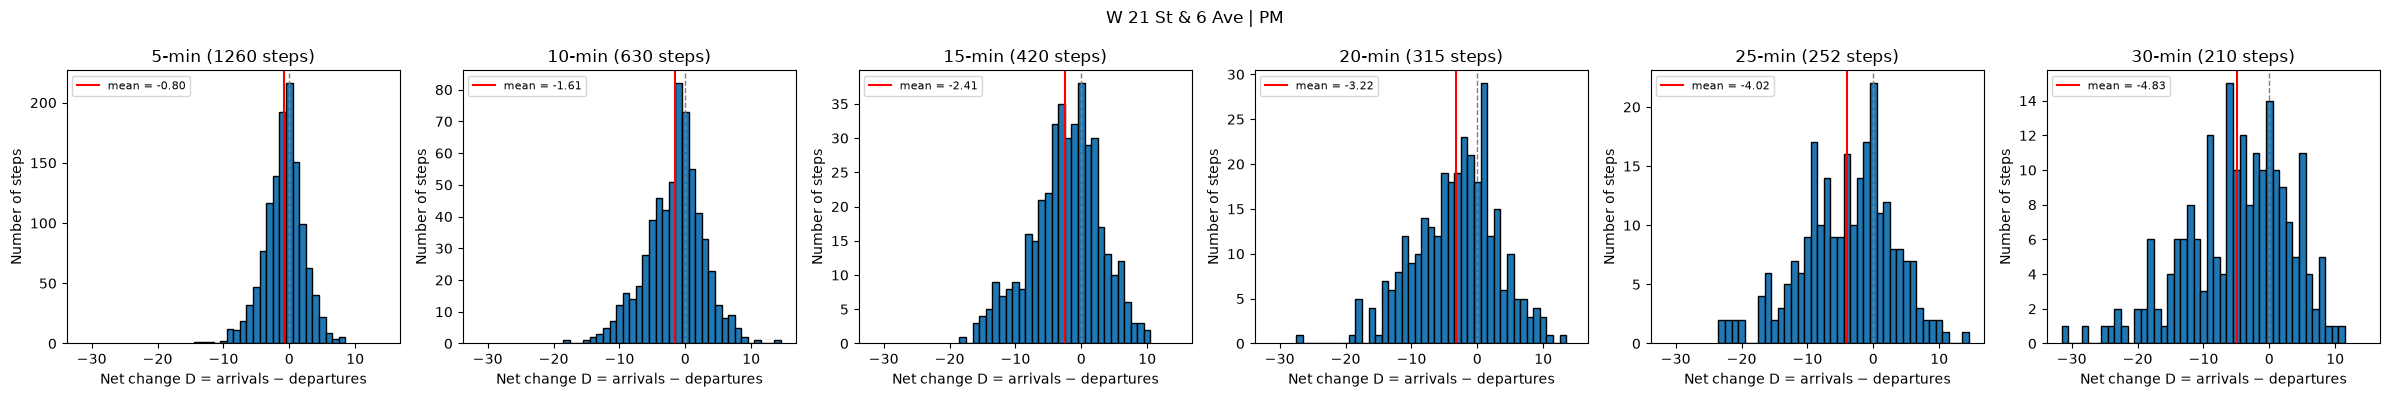

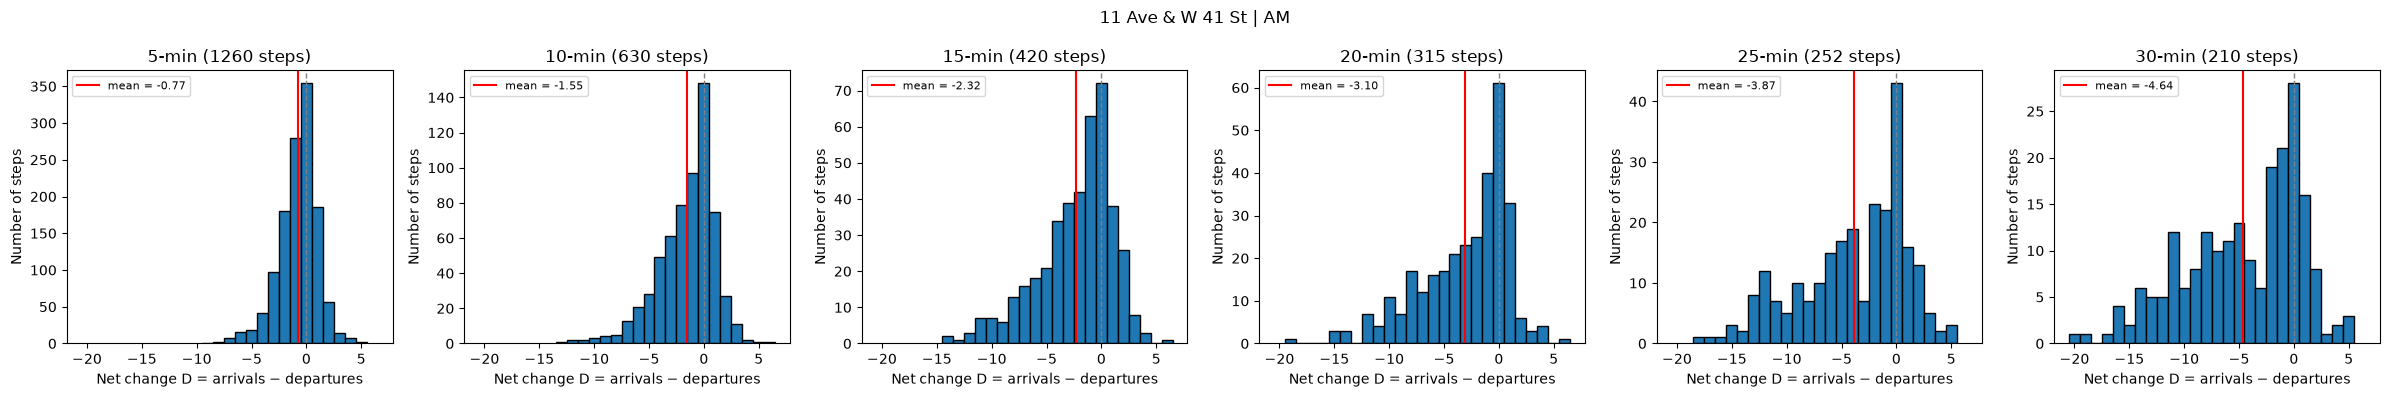

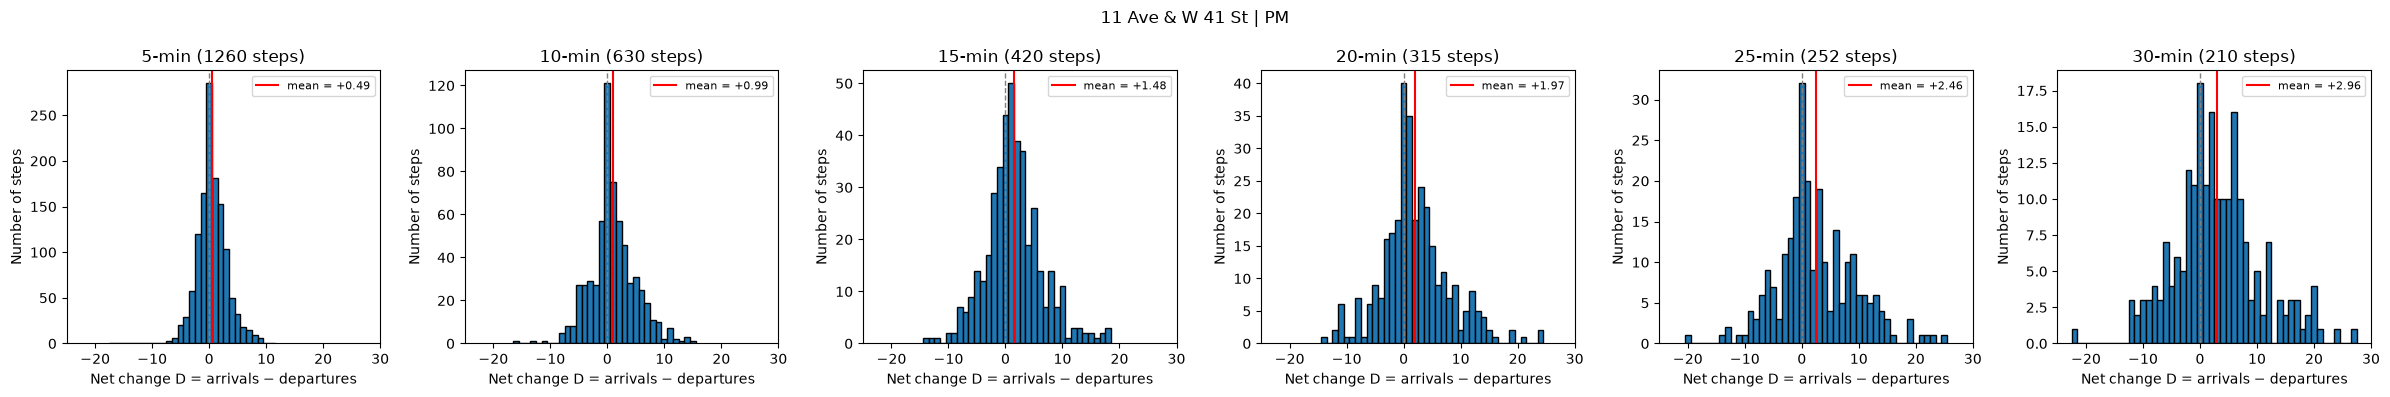

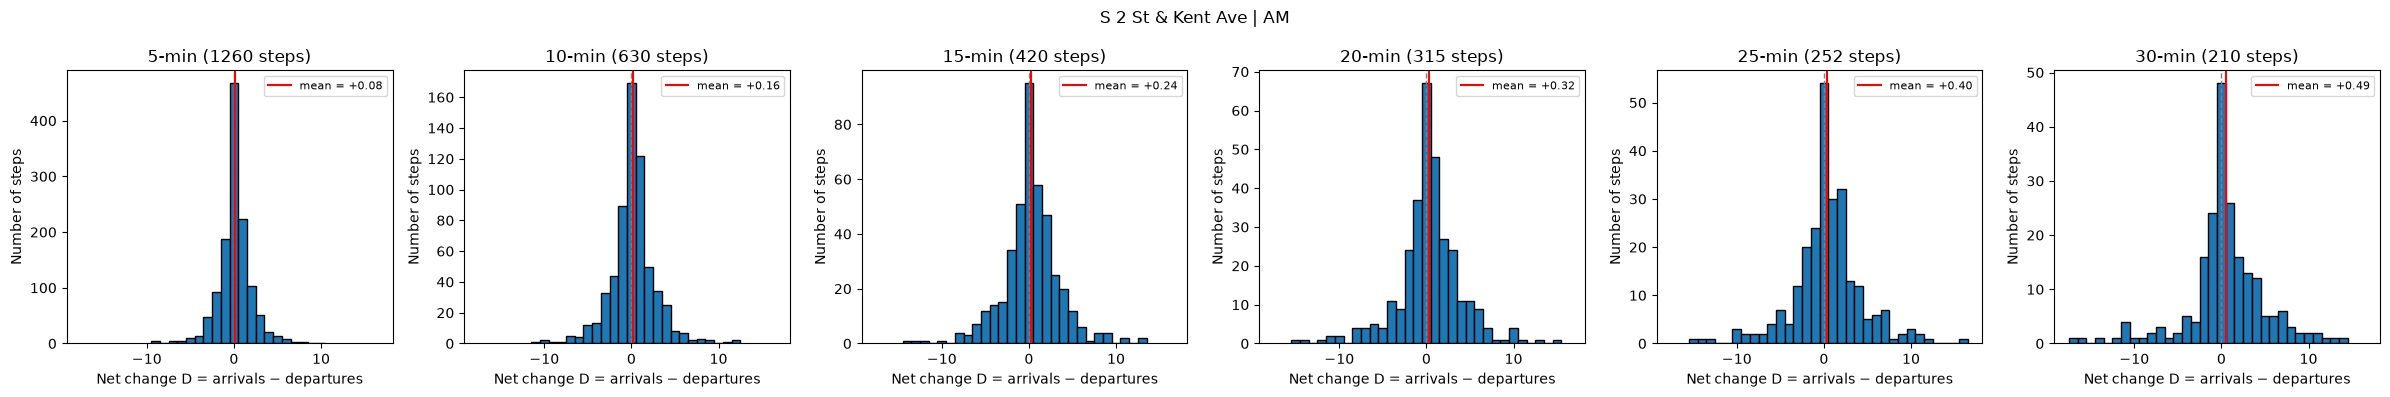

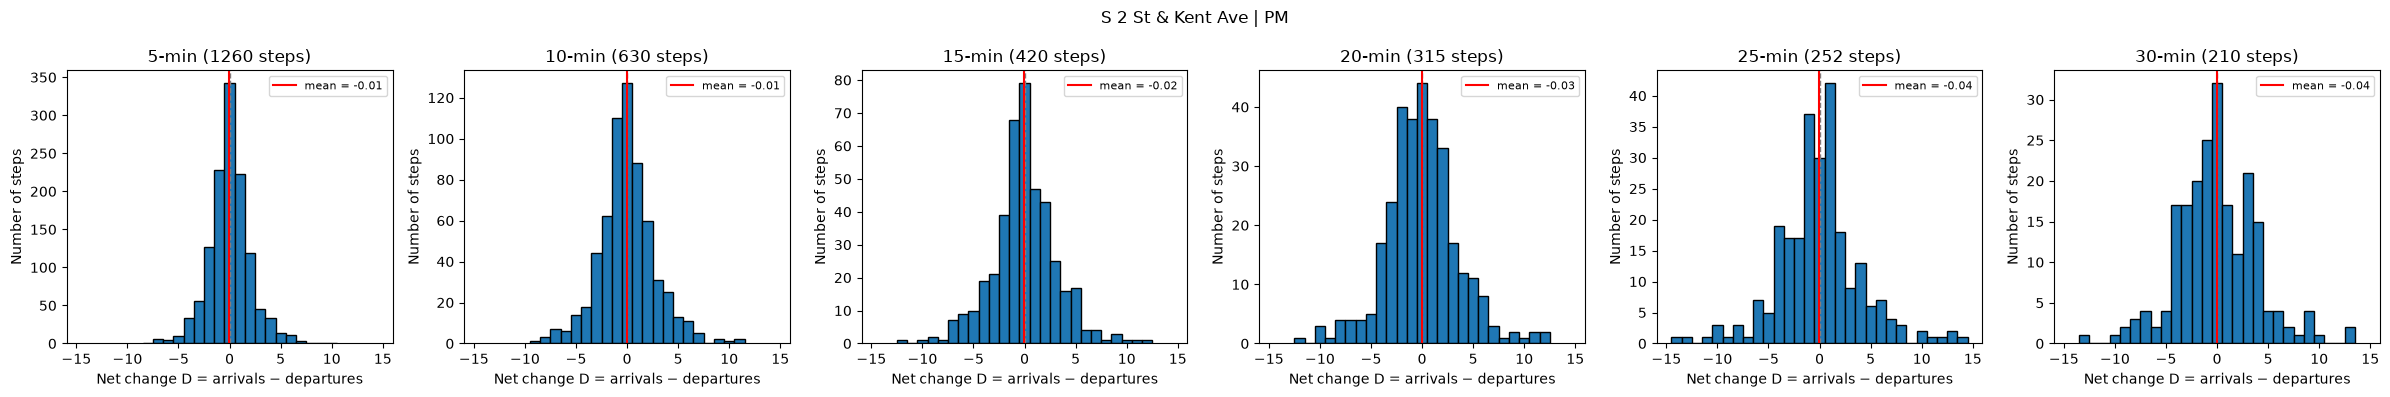

In [14]:
# ---------------------------------------------------------------------------
# Net-flow data. Determine net bike incoming/outgoing flow for each window
# ---------------------------------------------------------------------------
AUG_WEEKDAYS = pd.date_range("2026-08-01", "2026-08-31", freq="B")   # Mon–Fri, 21 days
def step_counts(times, hours, window, days=AUG_WEEKDAYS):
    """Number of events in each `window`-minute step of a block, for every day, in time order.
    Steps with no events are 0. Length = len(days) * (block minutes / window)."""
    block_len = len(hours) * 60
    assert block_len % window == 0, f"window ({window}) must divide the block length ({block_len} min)"
    n_steps = block_len // window

    minutes_in = (times - times.dt.normalize()).dt.total_seconds() / 60 - hours.start * 60
    in_block = (minutes_in >= 0) & (minutes_in < block_len)

    step = (minutes_in[in_block] // window).astype(int)
    date = times[in_block].dt.normalize()
    counts = step.groupby([date, step]).size()

    # Full grid of (day, step), so empty steps count as 0 and weekends drop out
    grid = pd.MultiIndex.from_product([days, range(n_steps)])
    return counts.reindex(grid, fill_value=0).to_numpy()


def net_flow_arrays(df, station, am_hours, pm_hours, window, days=AUG_WEEKDAYS):
    """Return (am_D, pm_D): arrivals - departures at `station` for every step in each block."""
    dep_times = df.loc[df["start_station_name"] == station, "started_at"]
    arr_times = df.loc[df["end_station_name"] == station, "ended_at"]
    am_D = step_counts(arr_times, am_hours, window, days) - step_counts(dep_times, am_hours, window, days)
    pm_D = step_counts(arr_times, pm_hours, window, days) - step_counts(dep_times, pm_hours, window, days)
    return am_D, pm_D


# ---------------------------------------------------------------------------
# Plotting
# ---------------------------------------------------------------------------

def plot_D_hist(D, title="", ax=None):
    """Histogram of a net-change array D, one bar per integer value."""
    D = np.asarray(D)
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))

    bins = np.arange(D.min() - 0.5, D.max() + 1.5, 1)   # one bin per integer, centered on it
    ax.hist(D, bins=bins, edgecolor="black")
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.axvline(D.mean(), color="red", linewidth=1.5, label=f"mean = {D.mean():+.2f}")
    ax.set_title(title)
    ax.set_xlabel("Net change D = arrivals − departures")
    ax.set_ylabel("Number of steps")
    ax.legend(fontsize=8)
    return ax


def plot_D_hist_row(arrays, labels, title="", panel_width=4):
    """Side-by-side D histograms, one panel per array (e.g. one per window length)."""
    fig, axes = plt.subplots(1, len(arrays), figsize=(panel_width * len(arrays), 4), sharex=True)
    for ax, D, label in zip(np.atleast_1d(axes), arrays, labels):
        plot_D_hist(D, title=label, ax=ax)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_window_comparison(df, station, windows, am_hours, pm_hours):
    """For one station, plot D histograms across window lengths: one row for AM, one for PM."""
    results = {w: net_flow_arrays(df, station, am_hours, pm_hours, w) for w in windows}   # w -> (am_D, pm_D)
    for b, block in enumerate(["AM", "PM"]):
        plot_D_hist_row([results[w][b] for w in windows],
                        [f"{w}-min ({len(results[w][b])} steps)" for w in windows],
                        title=f"{station} | {block}")

# D histograms across all test window lengths, for each station
for station in stations:
    plot_window_comparison(df, station, WINDOWS_TO_TEST, AM_HOURS, PM_HOURS)

## Building Markov Chains

In [15]:
# ---------------------------------------------------------------------------
# Transition matrices
# ---------------------------------------------------------------------------

def build_transition_matrix(D, capacity):
    """
    (capacity+1) x (capacity+1) transition matrix from an array of net changes D.
    P[i, j] = P(next state = j | current state = i) = P(D = j - i),
    with any move below 0 or above capacity counted as a move to 0 or capacity.
    """
    D = np.asarray(D)
    values, counts = np.unique(D, return_counts=True)
    probs = counts / counts.sum()                       # empirical P(D = d)

    P = np.zeros((capacity + 1, capacity + 1))
    for i in range(capacity + 1):
        next_states = np.clip(i + values, 0, capacity)  # impossible states → 0 or capacity
        np.add.at(P[i], next_states, probs)             # add, since several d values can land on the same j

    assert np.allclose(P.sum(axis=1), 1), "every row should sum to 1"
    return P


def build_station_matrices(am_D, pm_D, capacity):
    """Return a dict with the AM, PM, and combined transition matrices for one station."""
    return {
        "AM": build_transition_matrix(am_D, capacity),
        "PM": build_transition_matrix(pm_D, capacity),
        "Combined": build_transition_matrix(np.concatenate([am_D, pm_D]), capacity),
    }


def build_all_matrices(df, stations, capacities, am_hours, pm_hours, window):
    """
    Build the AM / PM / Combined transition matrices for every station.
    Returns (MCs, Ds):
      MCs[station][block] -> transition matrix
      Ds[station][block]  -> the net-change array it was built from
    """
    assert len(stations) == len(capacities), "need one capacity per station"
    MCs, Ds = {}, {}
    for station, capacity in zip(stations, capacities):
        am_D, pm_D = net_flow_arrays(df, station, am_hours, pm_hours, window)
        Ds[station] = {"AM": am_D, "PM": pm_D, "Combined": np.concatenate([am_D, pm_D])}
        MCs[station] = build_station_matrices(am_D, pm_D, capacity)
    return MCs, Ds

In [16]:
MCs, Ds = build_all_matrices(df, stations, station_capacities, AM_HOURS, PM_HOURS, WINDOW)

name_width = max(len(s) for s in stations)
for station, capacity in zip(stations, station_capacities):
    print(f"{station:<{name_width}} | capacity {capacity} | "
          f"steps AM {len(Ds[station]['AM'])}, PM {len(Ds[station]['PM'])} | "
          f"mean D AM {Ds[station]['AM'].mean():+.2f}, PM {Ds[station]['PM'].mean():+.2f} | "
          f"matrix shape {MCs[station]['AM'].shape}")

W 21 St & 6 Ave   | capacity 63 | steps AM 630, PM 630 | mean D AM +1.82, PM -1.61 | matrix shape (64, 64)
11 Ave & W 41 St  | capacity 48 | steps AM 630, PM 630 | mean D AM -1.55, PM +0.99 | matrix shape (49, 49)
S 2 St & Kent Ave | capacity 44 | steps AM 630, PM 630 | mean D AM +0.16, PM -0.01 | matrix shape (45, 45)
